In [17]:
from statsbombpy import sb

competitions = sb.competitions()
targets = competitions[
    (competitions["competition_name"] == "FIFA World Cup") & (competitions["season_name"] == "2022") |
    (competitions["competition_name"] == "UEFA Euro") & (competitions["season_name"] == "2024")
]
targets

[10/18/26 17:48:01] WARNING  C:\Users\camca\AppData\Local\Packages\PythonSoftwareFoundation.Python. warnings.py:109
                             3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\s                
                             tatsbombpy\api_client.py:27: NoAuthWarning: credentials were not                      
                             supplied. open data access only                                                       
                               warnings.warn(                                                                      
                                                                                                                   

,competition_id,season_id,country_name,competition_name,competition_gender,competition_youth,competition_international,season_name,match_updated,match_updated_360,match_available_360,match_available
30,43,106,International,FIFA World Cup,male,False,True,2022,2026-05-04T01:48:57.914346,2026-05-04T01:53:40.309717,2026-05-04T01:53:40.309717,2026-05-04T01:48:57.914346
73,55,282,Europe,UEFA Euro,male,False,True,2024,2026-05-01T19:54:25.846072,2026-05-01T19:58:06.077979,2026-05-01T19:58:06.077979,2026-05-01T19:54:25.846072


In [18]:
wc_row = competitions[(competitions["competition_name"] == "FIFA World Cup") & (competitions["season_name"] == "2022")].iloc[0]
euro_row = competitions[(competitions["competition_name"] == "UEFA Euro") & (competitions["season_name"] == "2024")].iloc[0]

matches_wc = sb.matches(competition_id=wc_row["competition_id"], season_id=wc_row["season_id"])
matches_euro = sb.matches(competition_id=euro_row["competition_id"], season_id=euro_row["season_id"])

print(matches_wc.shape, matches_euro.shape)
matches_wc.head()

[10/18/26 17:49:00] WARNING  C:\Users\camca\AppData\Local\Packages\PythonSoftwareFoundation.Python. warnings.py:109
                             3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\s                
                             tatsbombpy\api_client.py:27: NoAuthWarning: credentials were not                      
                             supplied. open data access only                                                       
                               warnings.warn(                                                                      
                                                                                                                   

                    WARNING  C:\Users\camca\AppData\Local\Packages\PythonSoftwareFoundation.Python. warnings.py:109
                             3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\s                
                             tatsbombpy\api_client.py:27: NoAuthWarning: credentials were not                      
                             supplied. open data access only                                                       
                               warnings.warn(                                                                      
                                                                                                                   

(64, 55) (51, 55)


,match_id,match_date,kick_off,home_score,away_score,match_status,match_status_360,last_updated,last_updated_360,match_week,...,home_manager_country_name,away_manager_id,away_manager_name,away_manager_nickname,away_manager_dob,away_manager_country_id,away_manager_country_name,data_version,shot_fidelity_version,xy_fidelity_version
0,3857276,2022-12-01,15:00:00.000,1,2,available,available,2026-05-04T01:46:04.664252,2026-05-04T01:50:33.318123,3,...,England,1000518,Walid Regragui,None,1975-09-23,154,Morocco,1.1.0,2,2
1,3857271,2022-11-21,13:00:00.000,6,2,available,available,2026-05-04T01:40:47.671394,2026-05-04T01:43:30.216315,1,...,England,645,Carlos Manuel Brito Leal Queiróz,Carlos Queiroz,1953-03-01,183,Portugal,1.1.0,2,2
2,3857296,2022-12-01,15:00:00.000,0,0,available,available,2026-05-04T01:44:02.255386,2026-05-04T01:50:06.343225,3,...,Croatia,263,Roberto Martínez Montoliú,Roberto Martínez,1973-07-13,214,Spain,1.1.0,2,2
3,3857274,2022-11-25,16:00:00.000,1,1,available,available,2026-05-04T01:43:00.444702,2026-05-04T01:50:07.646458,2,...,Netherlands,2881,Gustavo Julio Alfaro,Gustavo Alfaro,1962-08-14,11,Argentina,1.1.0,2,2
4,3857255,2022-12-01,19:00:00.000,2,1,available,available,2026-05-04T01:42:55.630428,2026-05-04T01:49:36.594944,3,...,Japan,793,Luis Enrique Martínez García,Luis Enrique,1970-05-08,214,Spain,1.1.0,2,2


Test sur un match : 

In [19]:
sample_match_id = matches_wc.iloc[0]["match_id"]
events_sample = sb.events(match_id=sample_match_id)

print(events_sample.shape)
events_sample["type"].value_counts()

[10/18/26 17:51:26] WARNING  C:\Users\camca\AppData\Local\Packages\PythonSoftwareFoundation.Python. warnings.py:109
                             3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\s                
                             tatsbombpy\api_client.py:27: NoAuthWarning: credentials were not                      
                             supplied. open data access only                                                       
                               warnings.warn(                                                                      
                                                                                                                   

(3388, 91)


type
Pass                 955
Ball Receipt*        868
Carry                782
Pressure             289
Ball Recovery         93
Duel                  63
Clearance             41
Dribble               39
Miscontrol            32
Foul Committed        31
Foul Won              31
Block                 27
Interception          23
Dispossessed          23
Dribbled Past         23
Goal Keeper           16
Shot                  12
Substitution          10
Tactical Shift         5
Half Start             4
Half End               4
Injury Stoppage        4
Referee Ball-Drop      4
50/50                  2
Starting XI            2
Error                  1
Shield                 1
Own Goal For           1
Own Goal Against       1
Offside                1
Name: count, dtype: int64

In [21]:
from pathlib import Path
import pandas as pd 

all_matches = pd.concat([
    matches_wc.assign(competition="WC2022"),
    matches_euro.assign(competition="Euro2024"),
])

events_list = []
for i, match_id in enumerate(all_matches["match_id"]):
    events = sb.events(match_id=match_id)
    events["match_id"] = match_id
    events_list.append(events)
    if (i + 1) % 10 == 0:
        print(f"{i + 1} / {len(all_matches)} matchs traités")

all_events = pd.concat(events_list, ignore_index=True)
print(all_events.shape)

Path("data").mkdir(exist_ok=True)
all_events.to_parquet("data/events_wc2022_euro2024.parquet")

[10/18/26 17:53:34] WARNING  C:\Users\camca\AppData\Local\Packages\PythonSoftwareFoundation.Python. warnings.py:109
                             3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\s                
                             tatsbombpy\api_client.py:27: NoAuthWarning: credentials were not                      
                             supplied. open data access only                                                       
                               warnings.warn(                                                                      
                                                                                                                   

[10/18/26 17:53:35] WARNING  C:\Users\camca\AppData\Local\Packages\PythonSoftwareFoundation.Python. warnings.py:109
                             3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\s                
                             tatsbombpy\api_client.py:27: NoAuthWarning: credentials were not                      
                             supplied. open data access only                                                       
                               warnings.warn(                                                                      
                                                                                                                   

                    WARNING  C:\Users\camca\AppData\Local\Packages\PythonSoftwareFoundation.Python. warnings.py:109
                             3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\s                
                             tatsbombpy\api_client.py:27: NoAuthWarning: credentials were not                      
                             supplied. open data access only                                                       
                               warnings.warn(                                                                      
                                                                                                                   

                    WARNING  C:\Users\camca\AppData\Local\Packages\PythonSoftwareFoundation.Python. warnings.py:109
                             3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\s                
                             tatsbombpy\api_client.py:27: NoAuthWarning: credentials were not                      
                             supplied. open data access only                                                       
                               warnings.warn(                                                                      
                                                                                                                   

                    WARNING  C:\Users\camca\AppData\Local\Packages\PythonSoftwareFoundation.Python. warnings.py:109
                             3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\s                
                             tatsbombpy\api_client.py:27: NoAuthWarning: credentials were not                      
                             supplied. open data access only                                                       
                               warnings.warn(                                                                      
                                                                                                                   

...

[10/18/26 17:55:05] WARNING  C:\Users\camca\AppData\Local\Packages\PythonSoftwareFoundation.Python. warnings.py:109
                             3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\s                
                             tatsbombpy\api_client.py:27: NoAuthWarning: credentials were not                      
                             supplied. open data access only                                                       
                               warnings.warn(                                                                      
                                                                                                                   

[10/18/26 17:55:06] WARNING  C:\Users\camca\AppData\Local\Packages\PythonSoftwareFoundation.Python. warnings.py:109
                             3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\s                
                             tatsbombpy\api_client.py:27: NoAuthWarning: credentials were not                      
                             supplied. open data access only                                                       
                               warnings.warn(                                                                      
                                                                                                                   

[10/18/26 17:55:07] WARNING  C:\Users\camca\AppData\Local\Packages\PythonSoftwareFoundation.Python. warnings.py:109
                             3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\s                
                             tatsbombpy\api_client.py:27: NoAuthWarning: credentials were not                      
                             supplied. open data access only                                                       
                               warnings.warn(                                                                      
                                                                                                                   

                    WARNING  C:\Users\camca\AppData\Local\Packages\PythonSoftwareFoundation.Python. warnings.py:109
                             3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\s                
                             tatsbombpy\api_client.py:27: NoAuthWarning: credentials were not                      
                             supplied. open data access only                                                       
                               warnings.warn(                                                                      
                                                                                                                   

(422561, 115)


CELULLE DE REPRISE DE CODE

In [2]:
import pandas as pd
import numpy as np
from statsbombpy import sb

all_events = pd.read_parquet("data/events_wc2022_euro2024.parquet")

competitions = sb.competitions()
wc_row = competitions[(competitions["competition_name"] == "FIFA World Cup") & (competitions["season_name"] == "2022")].iloc[0]
euro_row = competitions[(competitions["competition_name"] == "UEFA Euro") & (competitions["season_name"] == "2024")].iloc[0]

matches_wc = sb.matches(competition_id=wc_row["competition_id"], season_id=wc_row["season_id"])
matches_euro = sb.matches(competition_id=euro_row["competition_id"], season_id=euro_row["season_id"])
all_matches = pd.concat([matches_wc.assign(competition="WC2022"), matches_euro.assign(competition="Euro2024")])

print(all_events.shape, all_matches.shape)

C:\Users\camca\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\statsbombpy\api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(
C:\Users\camca\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\statsbombpy\api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(


(422561, 115) (115, 55)


In [3]:
def get_match_minutes(events, match_id):
    match_events = events[events["match_id"] == match_id]
    duration = match_events["minute"].max()

    starting = match_events[match_events["type"] == "Starting XI"]
    minutes = {}

    for _, row in starting.iterrows():
        for player in row["tactics"]["lineup"]:
            minutes[player["player"]["id"]] = {"name": player["player"]["name"], "on": 0, "off": duration}

    subs = match_events[match_events["type"] == "Substitution"]
    for _, row in subs.iterrows():
        off_id = row["player_id"]
        sub_minute = row["minute"]
        if off_id in minutes:
            minutes[off_id]["off"] = sub_minute
        if pd.notna(row.get("substitution_replacement_id")):
            on_id = row["substitution_replacement_id"]
            minutes[on_id] = {"name": row["substitution_replacement"], "on": sub_minute, "off": duration}

    return pd.DataFrame([
        {"match_id": match_id, "player_id": pid, "player_name": v["name"], "minutes_played": v["off"] - v["on"]}
        for pid, v in minutes.items()
    ])

minutes_list = [get_match_minutes(all_events, mid) for mid in all_matches["match_id"]]
player_minutes = pd.concat(minutes_list, ignore_index=True)

player_minutes_total = player_minutes.groupby(["player_id", "player_name"])["minutes_played"].sum().reset_index()
player_minutes_total.sort_values("minutes_played", ascending=False).head()

,player_id,player_name,minutes_played
57,3468.0,Jordan Pickford,1203
33,3244.0,John Stones,1182
101,3943.0,Declan Rice,1166
278,6704.0,Theo Bernard François Hernández,1150
436,10481.0,Aurélien Djani Tchouaméni,1150


In [4]:
import numpy as np

def dist_to_goal(loc):
    if loc is None or (isinstance(loc, float) and np.isnan(loc)):
        return np.nan
    x, y = loc
    return np.sqrt((120 - x) ** 2 + (40 - y) ** 2)

def is_progressive(start, end):
    d_start = dist_to_goal(start)
    d_end = dist_to_goal(end)
    if np.isnan(d_start) or np.isnan(d_end):
        return False
    gain = d_start - d_end
    own_half = start[0] < 60
    opp_half = end[0] >= 60
    if own_half and not opp_half:
        return gain >= 30
    elif own_half and opp_half:
        return gain >= 15
    else:
        return gain >= 10

ev = all_events.copy()

shots = ev[ev["type"] == "Shot"].copy()
shots["is_goal"] = shots["shot_outcome"] == "Goal"
shot_stats = shots.groupby("player_id").agg(
    shots=("id", "count"),
    goals=("is_goal", "sum"),
    xg=("shot_statsbomb_xg", "sum"),
).reset_index()

passes = ev[ev["type"] == "Pass"].copy()
passes["is_progressive"] = passes.apply(
    lambda r: is_progressive(r["location"], r["pass_end_location"])
    if isinstance(r["location"], list) and isinstance(r["pass_end_location"], list) else False,
    axis=1,
)
pass_stats = passes.groupby("player_id").agg(
    passes_completed=("pass_outcome", lambda x: x.isna().sum()),
    progressive_passes=("is_progressive", "sum"),
).reset_index()

carries = ev[ev["type"] == "Carry"].copy()
carries["is_progressive"] = carries.apply(
    lambda r: is_progressive(r["location"], r["carry_end_location"])
    if isinstance(r["location"], list) and isinstance(r["carry_end_location"], list) else False,
    axis=1,
)
carry_stats = carries.groupby("player_id").agg(progressive_carries=("is_progressive", "sum")).reset_index()

defensive_types = ["Interception", "Clearance", "Block", "Ball Recovery", "Pressure"]
defense = ev[ev["type"].isin(defensive_types)]
defense_stats = defense.groupby(["player_id", "type"]).size().unstack(fill_value=0).reset_index()

player_profiles = (
    player_minutes_total
    .merge(shot_stats, on="player_id", how="left")
    .merge(pass_stats, on="player_id", how="left")
    .merge(carry_stats, on="player_id", how="left")
    .merge(defense_stats, on="player_id", how="left")
    .fillna(0)
)

player_profiles.head()

,player_id,player_name,minutes_played,shots,goals,xg,passes_completed,progressive_passes,progressive_carries,Ball Recovery,Block,Clearance,Interception,Pressure
0,2941.0,Ismaïla Sarr,363,10.0,1.0,1.848790,57.0,0.0,0.0,17.0,4.0,1.0,3.0,51.0
1,2954.0,Youri Tielemans,260,4.0,1.0,0.153319,152.0,0.0,0.0,9.0,10.0,0.0,4.0,34.0
2,2972.0,Marcus Thuram,460,13.0,0.0,1.294312,78.0,0.0,0.0,14.0,8.0,5.0,4.0,72.0
3,2988.0,Memphis Depay,780,28.0,2.0,3.132957,208.0,0.0,0.0,18.0,8.0,1.0,2.0,120.0
4,2989.0,Alexander Djiku,109,0.0,0.0,0.000000,23.0,0.0,0.0,3.0,1.0,10.0,4.0,5.0


Progressives_passes et progressives_carries à 0 car position enregistré comme tableau numpy

In [5]:
def is_valid_loc(loc):
    if loc is None:
        return False
    if isinstance(loc, float) and np.isnan(loc):
        return False
    return hasattr(loc, "__len__") and len(loc) == 2

passes["is_progressive"] = passes.apply(
    lambda r: is_progressive(r["location"], r["pass_end_location"])
    if is_valid_loc(r["location"]) and is_valid_loc(r["pass_end_location"]) else False,
    axis=1,
)
pass_stats = passes.groupby("player_id").agg(
    passes_completed=("pass_outcome", lambda x: x.isna().sum()),
    progressive_passes=("is_progressive", "sum"),
).reset_index()

carries["is_progressive"] = carries.apply(
    lambda r: is_progressive(r["location"], r["carry_end_location"])
    if is_valid_loc(r["location"]) and is_valid_loc(r["carry_end_location"]) else False,
    axis=1,
)
carry_stats = carries.groupby("player_id").agg(progressive_carries=("is_progressive", "sum")).reset_index()

player_profiles = (
    player_minutes_total
    .merge(shot_stats, on="player_id", how="left")
    .merge(pass_stats, on="player_id", how="left")
    .merge(carry_stats, on="player_id", how="left")
    .merge(defense_stats, on="player_id", how="left")
    .fillna(0)
)

player_profiles.head()

,player_id,player_name,minutes_played,shots,goals,xg,passes_completed,progressive_passes,progressive_carries,Ball Recovery,Block,Clearance,Interception,Pressure
0,2941.0,Ismaïla Sarr,363,10.0,1.0,1.848790,57.0,20.0,18.0,17.0,4.0,1.0,3.0,51.0
1,2954.0,Youri Tielemans,260,4.0,1.0,0.153319,152.0,34.0,4.0,9.0,10.0,0.0,4.0,34.0
2,2972.0,Marcus Thuram,460,13.0,0.0,1.294312,78.0,12.0,17.0,14.0,8.0,5.0,4.0,72.0
3,2988.0,Memphis Depay,780,28.0,2.0,3.132957,208.0,60.0,18.0,18.0,8.0,1.0,2.0,120.0
4,2989.0,Alexander Djiku,109,0.0,0.0,0.000000,23.0,6.0,0.0,3.0,1.0,10.0,4.0,5.0


Filtre joueurs qui ont suffisemment de temps de jeu et normalisation de leur stats sur 90 min

In [6]:
MIN_MINUTES = 450

df = player_profiles[player_profiles["minutes_played"] >= MIN_MINUTES].copy()
df["nineties"] = df["minutes_played"] / 90

per90_cols = ["shots", "goals", "xg", "passes_completed", "progressive_passes",
              "progressive_carries", "Ball Recovery", "Block", "Clearance", "Interception", "Pressure"]

for col in per90_cols:
    df[f"{col}_p90"] = df[col] / df["nineties"]

df.shape

(130, 26)

Récupération des postes

In [8]:
all_lineups_valid = all_lineups.dropna(subset=["position"])

def most_common_position(x):
    counts = x.value_counts()
    return counts.idxmax() if len(counts) > 0 else None

player_positions = (
    all_lineups_valid.groupby("player_id")["position"]
    .agg(most_common_position)
    .reset_index()
)

df = df.merge(player_positions, on="player_id", how="left")
df[["player_name", "position"]].head(10)

,player_name,position
0,Marcus Thuram,Center Forward
1,Memphis Depay,Center Forward
2,Kylian Mbappé Lottin,Left Wing
3,Adrien Rabiot,Left Defensive Midfield
4,Christian Dannemann Eriksen,Left Center Midfield
5,Jan Vertonghen,Left Center Back
6,Kevin De Bruyne,Center Attacking Midfield
7,Nicolás Hernán Otamendi,Left Center Back
8,Hugo Lloris,Goalkeeper
9,Antonio Rüdiger,Right Center Back


Modélisation : Normalisatione et PCA

In [9]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

feature_cols = [c for c in df.columns if c.endswith("_p90")]
print(feature_cols)

X = df[feature_cols].fillna(0)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA(n_components=0.90)
X_pca = pca.fit_transform(X_scaled)

print("Nombre de composantes retenues :", X_pca.shape[1])
print("Variance expliquée cumulée :", pca.explained_variance_ratio_.cumsum())

['shots_p90', 'goals_p90', 'xg_p90', 'passes_completed_p90', 'progressive_passes_p90', 'progressive_carries_p90', 'Ball Recovery_p90', 'Block_p90', 'Clearance_p90', 'Interception_p90', 'Pressure_p90']
Nombre de composantes retenues : 7
Variance expliquée cumulée : [0.33172578 0.55350215 0.68448915 0.76751719 0.82629062 0.87455275
 0.91663365]


CLUSTERING

In [10]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

scores = {}
for k in range(3, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_pca)
    scores[k] = silhouette_score(X_pca, labels)

for k, s in scores.items():
    print(k, round(s, 3))

C:\Users\camca\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] Le fichier spécifié est introuvable
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\camca\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
  File "C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.10_3.10.3056.0_x64__qbz5n2kfra8p0\lib\subprocess.py", line 503, in run
    with Popen(*popenargs, **kwargs) as process:
  File "C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.10

3 0.34
4 0.3
5 0.273
6 0.247
7 0.252
8 0.24
9 0.247
10 0.246


In [11]:
k_final = 4
km_final = KMeans(n_clusters=k_final, random_state=42, n_init=10)
df["cluster"] = km_final.fit_predict(X_pca)

df["cluster"].value_counts().sort_index()

cluster
0    48
1    16
2    14
3    52
Name: count, dtype: int64

In [12]:
pd.crosstab(df["cluster"], df["position"])

position,Center Attacking Midfield,Center Back,Center Defensive Midfield,Center Forward,Goalkeeper,Left Back,Left Center Back,Left Center Forward,Left Center Midfield,Left Defensive Midfield,Left Midfield,Left Wing,Left Wing Back,Right Back,Right Center Back,Right Center Forward,Right Center Midfield,Right Defensive Midfield,Right Wing,Right Wing Back
cluster,,,,,,,,,,,,,,,,,,,,
0,0,2,0,0,0,6,13,0,0,2,0,0,1,5,15,0,0,2,0,2
1,0,0,0,10,0,0,0,2,0,0,0,3,0,0,0,1,0,0,0,0
2,0,0,0,0,14,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,6,0,3,2,0,2,0,0,4,6,1,7,2,4,0,0,6,4,4,1


TEST DE SIMILARITE DE JOUEUR

In [28]:
from sklearn.metrics.pairwise import cosine_similarity

similarity_matrix = cosine_similarity(X_pca)

def find_similar_players(player_name, n=5):
    idx = df.index[df["player_name"] == player_name]
    if len(idx) == 0:
        print("Joueur non trouvé")
        return None
    idx = idx[0]
    scores = similarity_matrix[df.index.get_loc(idx)]
    similar_idx = scores.argsort()[::-1][1:n+1]
    return df.iloc[similar_idx][["player_name", "position", "cluster"]].assign(similarity=scores[similar_idx])

find_similar_players("Rodrigo Hernández Cascante")

,player_name,position,cluster,similarity
9,Antonio Rüdiger,Right Center Back,0,0.912112
76,João Pedro Cavaco Cancelo,Right Back,3,0.790839
100,Kléper Laveran Lima Ferreira,Right Center Back,0,0.740630
21,Granit Xhaka,Left Defensive Midfield,0,0.699297
22,Pierre-Emile Højbjerg,Left Defensive Midfield,3,0.663977


Outils pour trouver le nom complet du joueur

In [27]:
df[df["player_name"].str.contains("Rodri", case=False, na=False)]

,player_id,player_name,minutes_played,shots,goals,xg,passes_completed,progressive_passes,progressive_carries,Ball Recovery,...,passes_completed_p90,progressive_passes_p90,progressive_carries_p90,Ball Recovery_p90,Block_p90,Clearance_p90,Interception_p90,Pressure_p90,position,cluster
71,6765.0,Rodrigo Hernández Cascante,955,6.0,1.0,0.196675,1055.0,102.0,25.0,48.0,...,99.424084,9.612565,2.356021,4.523560,1.696335,2.167539,0.659686,10.083770,Right Center Back,0
79,7797.0,Rodrigo Javier De Paul,631,7.0,0.0,0.570043,475.0,74.0,22.0,37.0,...,67.749604,10.554675,3.137876,5.277338,1.141046,0.570523,1.426307,15.832013,Right Center Midfield,3


Radar de similarité

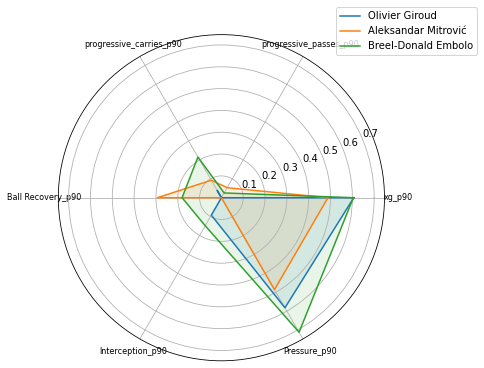

In [33]:
def plot_radar_for(search_term, n_similar=2):
    matches = df[df["player_name"].str.contains(search_term, case=False, na=False)]
    if len(matches) == 0:
        print("Joueur non trouvé")
        return
    main_name = matches.iloc[0]["player_name"]

    similar = find_similar_players(search_term, n=n_similar)
    names_to_plot = [main_name] + similar["player_name"].tolist()

    players_to_plot = df[df["player_name"].isin(names_to_plot)].drop_duplicates(subset="player_name")
    radar_df = players_to_plot.set_index("player_name")[radar_cols]
    radar_norm = (radar_df - df[radar_cols].min()) / (df[radar_cols].max() - df[radar_cols].min())

    angles = np.linspace(0, 2 * np.pi, len(radar_cols), endpoint=False).tolist()
    angles += angles[:1]

    fig, ax = plt.subplots(figsize=(6, 6), subplot_kw=dict(polar=True))
    for name, row in radar_norm.iterrows():
        values = row.tolist()
        values += values[:1]
        ax.plot(angles, values, label=name)
        ax.fill(angles, values, alpha=0.1)

    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(radar_cols, fontsize=8)
    ax.legend(loc="upper right", bbox_to_anchor=(1.3, 1.1))
    plt.show()

plot_radar_for("Olivier Giroud")

In [34]:
import pickle

with open("data/player_profiles.pkl", "wb") as f:
    pickle.dump({
        "df": df,
        "X_pca": X_pca,
        "similarity_matrix": similarity_matrix,
        "radar_cols": radar_cols,
    }, f)

Récupération données joueurs

In [35]:
team_list = []
for match_id in all_matches["match_id"]:
    lineup = sb.lineups(match_id=match_id)
    for team_name, team_df in lineup.items():
        team_df = team_df.copy()
        team_df["team"] = team_name
        team_list.append(team_df[["player_id", "team"]])

all_teams = pd.concat(team_list, ignore_index=True).drop_duplicates(subset="player_id")
df = df.merge(all_teams, on="player_id", how="left")

competition_map = all_matches.set_index("match_id")["competition"].to_dict()
player_competition = (
    player_minutes[["match_id", "player_id"]]
    .assign(competition=lambda x: x["match_id"].map(competition_map))
    .groupby("player_id")["competition"]
    .agg(lambda x: " + ".join(sorted(set(x))))
    .reset_index()
)
df = df.merge(player_competition, on="player_id", how="left")

from sklearn.decomposition import PCA as PCA2D
coords_2d = PCA2D(n_components=2, random_state=42).fit_transform(X_scaled)
df["pca_x"] = coords_2d[:, 0]
df["pca_y"] = coords_2d[:, 1]

df[["player_name", "team", "competition", "position"]].head()

C:\Users\camca\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\statsbombpy\api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(
C:\Users\camca\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\statsbombpy\api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(
C:\Users\camca\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\statsbombpy\api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(
C:\Users\camca\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\statsbombpy\api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
 

,player_name,team,competition,position
0,Marcus Thuram,France,Euro2024 + WC2022,Center Forward
1,Memphis Depay,Netherlands,Euro2024 + WC2022,Center Forward
2,Kylian Mbappé Lottin,France,Euro2024 + WC2022,Left Wing
3,Adrien Rabiot,France,Euro2024 + WC2022,Left Defensive Midfield
4,Christian Dannemann Eriksen,Denmark,Euro2024 + WC2022,Left Center Midfield


In [36]:
with open("data/player_profiles.pkl", "wb") as f:
    pickle.dump({
        "df": df,
        "similarity_matrix": similarity_matrix,
        "radar_cols": radar_cols,
    }, f)

Ajout d'information sur le comportement 

In [41]:
bad_behaviour = ev[ev["type"] == "Bad Behaviour"].copy()
bad_behaviour["is_card"] = bad_behaviour["bad_behaviour_card"].notna()

fouls = ev[ev["type"] == "Foul Committed"].copy()
fouls["is_card"] = fouls["foul_committed_card"].notna()
fouls["is_red"] = fouls["foul_committed_card"].isin(["Red Card", "Second Yellow"])

cards_from_fouls = fouls.groupby("player_id").agg(
    fouls_committed=("id", "count"),
    cards_from_fouls=("is_card", "sum"),
    red_cards=("is_red", "sum"),
).reset_index()

cards_from_bad_behaviour = bad_behaviour.groupby("player_id").agg(
    cards_from_bad_behaviour=("is_card", "sum"),
).reset_index()

fouls_won_stats = ev[ev["type"] == "Foul Won"].groupby("player_id").size().reset_index(name="fouls_won")

df = (
    df
    .merge(cards_from_fouls, on="player_id", how="left")
    .merge(cards_from_bad_behaviour, on="player_id", how="left")
    .merge(fouls_won_stats, on="player_id", how="left")
    .fillna(0)
)

df["total_cards"] = df["cards_from_fouls"] + df["cards_from_bad_behaviour"]
df["yellow_cards"] = df["total_cards"] - df["red_cards"]
df["cards_p90"] = df["total_cards"] / df["nineties"]
df["fouls_committed_p90"] = df["fouls_committed"] / df["nineties"]

df[["player_name", "total_cards", "yellow_cards", "red_cards", "fouls_committed", "fouls_won", "cards_p90"]].sort_values("total_cards", ascending=False).head(10)

,player_name,total_cards,yellow_cards,red_cards,fouls_committed,fouls_won,cards_p90
82,Denzel Dumfries,4.0,4.0,0.0,29.0,15.0,0.364742
78,Silvan Widmer,4.0,4.0,0.0,9.0,3.0,0.609137
88,Aurélien Djani Tchouaméni,3.0,3.0,0.0,16.0,18.0,0.234783
69,Saša Lukić,3.0,3.0,0.0,18.0,2.0,0.574468
71,Rodrigo Hernández Cascante,3.0,3.0,0.0,14.0,8.0,0.282723
64,Daniel Carvajal Ramos,3.0,2.0,1.0,6.0,5.0,0.423197
52,Fabian Lukas Schär,3.0,3.0,0.0,8.0,6.0,0.416025
60,Nikola Milenković,3.0,3.0,0.0,14.0,4.0,0.467128
3,Adrien Rabiot,3.0,3.0,0.0,15.0,14.0,0.297685
43,Mateo Kovačić,2.0,2.0,0.0,6.0,23.0,0.205011


In [4]:
with open("data/player_profiles.pkl", "wb") as f:
    pickle.dump({
        "df": df,
        "similarity_matrix": similarity_matrix,
        "radar_cols": radar_cols,
    }, f)

In [43]:
bad_behaviour["is_red"] = bad_behaviour["bad_behaviour_card"].isin(["Red Card", "Second Yellow"])

red_from_bad_behaviour = bad_behaviour.groupby("player_id").agg(
    cards_from_bad_behaviour=("is_card", "sum"),
    red_from_bad_behaviour=("is_red", "sum"),
).reset_index()

df = df.drop(columns=["cards_from_bad_behaviour"], errors="ignore")
df = df.merge(red_from_bad_behaviour, on="player_id", how="left").fillna(0)

df["total_cards"] = df["cards_from_fouls"] + df["cards_from_bad_behaviour"]
df["red_cards"] = df["red_cards"] + df["red_from_bad_behaviour"]
df["yellow_cards"] = df["total_cards"] - df["red_cards"]
df["cards_p90"] = df["total_cards"] / df["nineties"]

df[df["player_name"].str.contains("Dumfries")][["player_name", "total_cards", "yellow_cards", "red_cards"]]

,player_name,total_cards,yellow_cards,red_cards
82,Denzel Dumfries,4.0,3.0,1.0


Ajout de Feature : pourcentile

In [45]:
def position_group(pos):
    if pos is None or pd.isna(pos):
        return "Unknown"
    pos = str(pos)
    if "Goalkeeper" in pos:
        return "Goalkeeper"
    if "Back" in pos:
        return "Defender"
    if "Midfield" in pos:
        return "Midfielder"
    if "Wing" in pos or "Forward" in pos:
        return "Attacker"
    return "Other"

df["position_group"] = df["position"].apply(position_group)
df["position_group"].value_counts()

position_group
Defender      53
Midfielder    34
Attacker      29
Goalkeeper    14
Name: count, dtype: int64

In [46]:
percentile_cols = [c for c in df.columns if c.endswith("_p90")]

for col in percentile_cols:
    df[f"{col}_pct"] = df.groupby("position_group")[col].rank(pct=True) * 100

df[["player_name", "position_group", "xg_p90_pct", "progressive_passes_p90_pct"]].head()

,player_name,position_group,xg_p90_pct,progressive_passes_p90_pct
0,Marcus Thuram,Attacker,44.827586,20.689655
1,Memphis Depay,Attacker,65.517241,65.517241
2,Kylian Mbappé Lottin,Attacker,86.206897,55.172414
3,Adrien Rabiot,Midfielder,47.058824,44.117647
4,Christian Dannemann Eriksen,Midfielder,67.647059,97.058824


On récupère les ages et valeurs marchandes 

In [2]:
import pandas as pd
import pickle

with open("data/player_profiles.pkl", "rb") as f:
    data = pickle.load(f)

df = data["df"]
similarity_matrix = data["similarity_matrix"]
radar_cols = data["radar_cols"]

df.shape

(130, 66)

In [3]:
import requests
import time
from datetime import date

HEADERS = {"User-Agent": "DataScienceFootProject/1.0 (projet étudiant Polytech Nice, contact: camille.veillon@etu.unice.fr)"}

def get_birthdate(player_name):
    try:
        search = requests.get(
            "https://www.wikidata.org/w/api.php",
            params={"action": "wbsearchentities", "search": player_name, "language": "en", "format": "json", "type": "item"},
            headers=HEADERS, timeout=5,
        ).json()
        if not search.get("search"):
            return None
        entity_id = search["search"][0]["id"]

        claims = requests.get(
            "https://www.wikidata.org/w/api.php",
            params={"action": "wbgetclaims", "entity": entity_id, "property": "P569", "format": "json"},
            headers=HEADERS, timeout=5,
        ).json()
        dob_str = claims["claims"]["P569"][0]["mainsnak"]["datavalue"]["value"]["time"]
        return dob_str[1:11]
    except Exception:
        return None

birthdates = {}
for name in df["player_name"]:
    birthdates[name] = get_birthdate(name)
    time.sleep(0.3)

df["birthdate"] = df["player_name"].map(birthdates)
df["birthdate"] = pd.to_datetime(df["birthdate"], errors="coerce")
today = pd.Timestamp("2026-10-19")
df["age"] = ((today - df["birthdate"]).dt.days / 365.25).round(1)

df[["player_name", "birthdate", "age"]].head(10)

,player_name,birthdate,age
0,Marcus Thuram,1997-08-06,29.2
1,Memphis Depay,1994-02-13,32.7
2,Kylian Mbappé Lottin,1998-12-20,27.8
3,Adrien Rabiot,1995-04-03,31.5
4,Christian Dannemann Eriksen,1992-02-14,34.7
5,Jan Vertonghen,1987-04-24,39.5
6,Kevin De Bruyne,1991-06-28,35.3
7,Nicolás Hernán Otamendi,1988-02-12,38.7
8,Hugo Lloris,1986-12-26,39.8
9,Antonio Rüdiger,1993-03-03,33.6
